# Modelling Time Dependent Arrivals

In many **discrete-event simulation** models the random arrivals of entities follow a time dependent distribution.  For example, arrivals of patients to an emergency department or arrivals of calls to a call centre may vary across the day.  Take for example, that chart below. Here the expected no. of patients arriving to a healthcare system increases from when the service opens to a peak and then reduces again towards the end of the day. 

<img src="Example_Time_Dependent_Dist.png"  alt="Example time dependent distribution">

When each interval is an Exponential distribution we call the arrivals a Non-Stationary Poisson Process (NSPP).  Due to way time progresses in DES software i.e. time until the next event, a NSPP must be sampled carefully. One particular challenge is sampling appropriate arrival times when moving from a slow moving interval to a fast moving interval where many more arrivals are expected. A naive sampling approach where we updated the parameter of an Exponential after each event can result in too few samples occuring in the fast moving interval.

`sim-tools` provides two ways to model NSPP.

* `time_dependent.NSPPThinning` based on the famous **Thinning** acceptance-rejection approach.
* `time_dependent.NSPPDirect` based on the Harrod and Kelton's **Direct Algorithm** that inverts the cumulative arrival rate function.

## 1. Thinning

Thinning is an acceptance-rejection approach to sampling inter-arrival times (IAT) from a time dependent distribution where each time period follows its own exponential distribution.

There are two random variables employed in sampling: an exponential distribution (used to sample IAT) and a uniform distibution (used to accept/reject samples).

All IATs are sampled from an Exponential distribution with the highest arrival rate (most frequent). These arrivals are then rejected (thinned) proportional to the ratio of the current arrival rate to the maximum arrival rate.  The algorithm executes until a sample is accepted.  The IAT returned is the sum of all the IATs that were sampled.

```{note}
As of v0.9.0 you only need to provide an arrival data set containing two columns

* `t`: the time period e.g. 0, 60, 120 minutes or 0, 1, 2 hours
* `mean_iat`: the **mean interval arrival time (IAT)** for the time period.
```

### 1.2 The thinning algorithm

A NSPP has arrival rate $\lambda(t)$ where $0 \leq t \leq T$

Here $i$ is the arrival number and $\mathcal{T_i}$ is its arrival time.

1. Let $\lambda^* = \max_{0 \leq t \leq T}\lambda(t)$ be the maximum of the arrival rate function and set $t = 0$ and $i=1$

2. Generate $e$ from the exponential distribution with rate $\lambda^*$ and let $t = t + e$ (this is the time of the next entity will arrive)

3. Generate $u$ from the $U(0,1)$ distribution.  If $u \leq \dfrac{\lambda(t)}{\lambda^*}$ then $\mathcal{T_i} =t$ and $i = i + 1$

4. Go to Step 2.

> The above is adapted from Banks et al.

### 1.3 `sim-tools` imports

In [1]:
# pylint: disable=missing-module-docstring,invalid-name
import numpy as np
import matplotlib.pyplot as plt

from sim_tools.datasets import load_banks_et_al_nspp
from sim_tools.time_dependent import (
    NSPPThinning,
    nspp_plot,
    nspp_simulation
)

In [2]:
# ggplot style for plots
plt.style.use("ggplot")

### 1.4 The Banks et al dataset

We will illustrate the use of `NSPPThinning` using an example from Banks et al. 

The table below breaks an arrival process down into 60 minutes intervals.


| t(min) | Mean time between arrivals (min) | Arrival Rate $\lambda(t)$ (arrivals/min) |
|:------:|:--------------------------------:|:--------------------------------------:|
|    0   |                15                |                  1/15                  |
|   60   |                12                |                  1/12                  |
|   120  |                 7                |                   1/7                  |
|   180  |                 5                |                   1/5                  |
|   240  |                 8                |                   1/8                  |
|   300  |                10                |                  1/10                  |
|   360  |                15                |                  1/15                  |
|   420  |                20                |                  1/20                  |
|   480  |                20                |                  1/20                  |



> **Interpretation**: In the table above the fastest arrival rate is 1/5 customers per minute or 5 minutes between customer arrivals.

In [5]:
# load the banks et al dataset
banks_data = load_banks_et_al_nspp()
banks_data

,t,mean_iat,arrival_rate
0,0,15,0.066667
1,60,12,0.083333
2,120,7,0.142857
3,180,5,0.200000
4,240,8,0.125000
5,300,10,0.100000
6,360,15,0.066667
7,420,20,0.050000
8,480,20,0.050000


The `NSPPThinning` class does not require the `arrival_rate` column. Internally it assumes that intervals are equal and uses the 1st and 2nd rows of the `t` column to calculate width (override with the `interval_width` parameter).  As the IAT is the inverse of the rate it thins the arrivals using 

$$ u \leq \dfrac{IAT_{min}}{IAT(t)}$$


### 1.5 Initialising a `NSPThinning` object

To initialise an `NSPThinning` object to produce reproducible samples we need to provide two random seeds and also pass in `data`

In [6]:
# create arrivals and set random number seeds
seeds = np.random.SeedSequence(42).spawn(2)

# create the arrival distribution object
arrivals = NSPPThinning(
    data=banks_data,
    random_seed1=seeds[0],
    random_seed2=seeds[1]
)

arrivals

NSPPThinning(data=     t  mean_iat  arrival_rate
0    0        15      0.066667
1   60        12      0.083333
2  120 ..., interval=60.0)

Call the `sample(simulation_time)` method to generate the next inter-arrival time (IAT). Note that `NSPPThinning` objects are stateless/memoryless i.e. it does not track the current simulation time or what has been sample prior. We therefore pass the current simulation time as a parameter to the method.

The code below samples 15 inter-arrival times.

In [7]:
# number of arrivals to simulate
n_arrivals = 15

# run simulation
simulation_time = 0.0
for _ in range(n_arrivals):

    # pass the current simulation time
    iat = arrivals.sample(simulation_time)

    # update of simulation time
    simulation_time += iat
    print(f"{simulation_time:.2f} Patient arrival (IAT={iat:.2f})")

13.99 Patient arrival (IAT=13.99)
17.66 Patient arrival (IAT=3.67)
35.86 Patient arrival (IAT=18.20)
58.99 Patient arrival (IAT=23.13)
100.76 Patient arrival (IAT=41.77)
101.44 Patient arrival (IAT=0.68)
105.10 Patient arrival (IAT=3.66)
122.12 Patient arrival (IAT=17.02)
124.29 Patient arrival (IAT=2.17)
134.67 Patient arrival (IAT=10.39)
141.57 Patient arrival (IAT=6.90)
142.65 Patient arrival (IAT=1.08)
145.18 Patient arrival (IAT=2.53)
146.81 Patient arrival (IAT=1.63)
157.24 Patient arrival (IAT=10.43)


Internally `NSPPThinning` assumes equally spaced intervals and calculates the interval width based on the difference between the first and second entries in the `data` parameter. Alternatively you can set the interval width manually:

In [8]:
# create arrivals and set random number seeds
seeds = np.random.SeedSequence(42).spawn(2)
arrivals = NSPPThinning(
    data=banks_data,
    interval_width=60,
    random_seed1=seeds[0],
    random_seed2=seeds[1]
)

arrivals

NSPPThinning(data=     t  mean_iat  arrival_rate
0    0        15      0.066667
1   60        12      0.083333
2  120 ..., interval=60)

### 1.6 Verify that your NSPP is working as expected

As part of model testing you can check that the NSPP for arrivals has been setup correctly by using `nspp_plot`. This runs multiple replications of the NSPP and returns a plot of the number of arrivals per interval.  The profile can be used as a sense check.  If you prefer to have the data in tabular form you can use `nspp_simulation` that returns a `pd.DataFrame` containing multiple replications of the number of arrivals per interval.

It is easy to make mistakes with time dependent distributions. Make sure you test your input data is modelled as expected in `sim-tools> `

#### NSPP plot

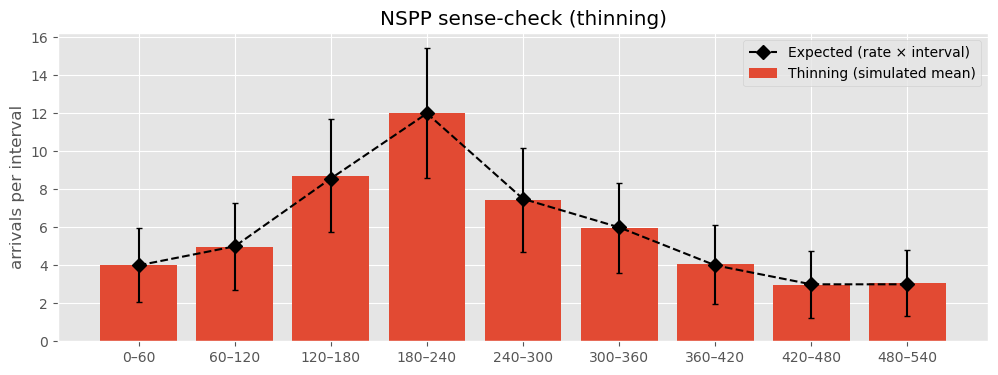

In [10]:
fig, ax = nspp_plot(banks_data, run_length=540, n_reps=1000)

#### Tabular NSPP data

The function `nspp_simulation` returns a `pd.DataFrame`. By default 1000 replications of the NSPP are run.  The run length can be specified, but if omitted it defaults to the last interval + interval width in the arrival profile.

In the Banks et al. example we are given the rate per minute of arrivals. We therefore multiply this by 60 get the expected number of arrivals in an hour.  We compare this to the actual simulated.

In [11]:
nspp_replications = nspp_simulation(banks_data, run_length=540, n_reps=1000)

# peak at data
nspp_replications.head()

,0,1,2,3,4,5,6,7,8
rep,,,,,,,,,
1,1,5,7,13,9,10,5,2,1
2,6,7,4,9,5,8,5,1,3
3,3,2,8,13,4,5,2,0,5
4,4,2,8,10,7,7,5,1,9
5,2,4,10,13,9,6,8,4,5


In [13]:
# re-label columns
nspp_replications.columns = banks_data["t"].values


## banks data converted from arrivasl per min to arrivals per hour
banks_data["expected_mean_arrivals_hr"] = banks_data["arrival_rate"] * 60.0
banks_data["simulated_mean_arrivals_hr"] = nspp_replications.mean(axis=0).values
banks_data.round(1)

,t,mean_iat,arrival_rate,expected_mean_arrivals_hr,simulated_mean_arrivals_hr
0,0,15,0.1,4.0,4.0
1,60,12,0.1,5.0,5.0
2,120,7,0.1,8.6,8.7
3,180,5,0.2,12.0,12.0
4,240,8,0.1,7.5,7.4
5,300,10,0.1,6.0,6.0
6,360,15,0.1,4.0,4.1
7,420,20,0.0,3.0,3.0
8,480,20,0.0,3.0,3.1


## The direct algorithm

In [14]:
data2 = banks_data.copy()
data2["t"] = [60, 120, 180, 240, 300, 360, 420, 480, 540]

In [15]:
from sim_tools.time_dependent import (
    NSPPDirect,
    nspp_direct_plot,
    nspp_direct_simulation
)

In [16]:
nspp_replications = nspp_direct_simulation(data2, n_reps=1000)

# peak at data
nspp_replications.head()

,0,1,2,3,4,5,6,7,8
rep,,,,,,,,,
1,4,4,9,13,6,7,3,1,4
2,4,4,6,13,15,11,4,1,4
3,5,6,5,12,10,5,4,4,5
4,5,7,7,16,8,11,3,2,5
5,5,11,8,11,10,8,0,3,2


In [18]:
# re-label columns
nspp_replications.columns = data2["t"].values


## banks data converted from arrivasl per min to arrivals per hour
data2["expected_mean_arrivals_hr"] = data2["arrival_rate"] * 60.0
data2["simulated_mean_arrivals_hr"] = nspp_replications.mean(axis=0).values
data2.round(2)

,t,mean_iat,arrival_rate,expected_mean_arrivals_hr,simulated_mean_arrivals_hr
0,60,15,0.07,4.00,3.95
1,120,12,0.08,5.00,4.98
2,180,7,0.14,8.57,8.52
3,240,5,0.20,12.00,12.10
4,300,8,0.12,7.50,7.58
5,360,10,0.10,6.00,6.02
6,420,15,0.07,4.00,4.01
7,480,20,0.05,3.00,2.96
8,540,20,0.05,3.00,2.96


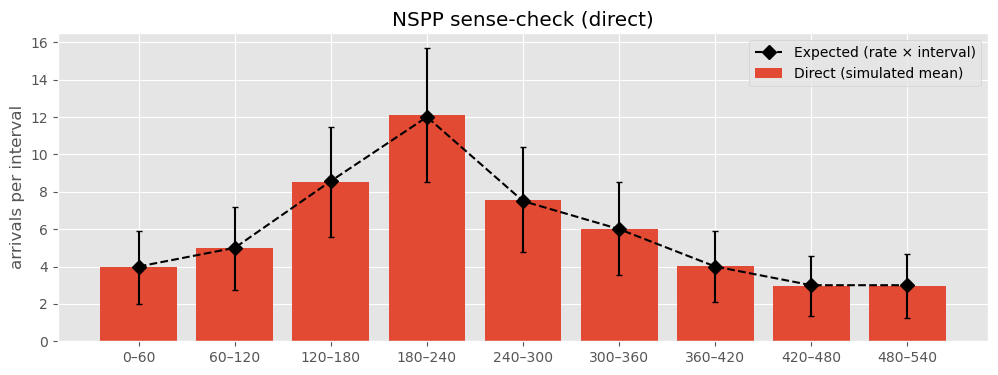

In [19]:
fig, ax = nspp_direct_plot(data2, run_length=540, n_reps=1000)

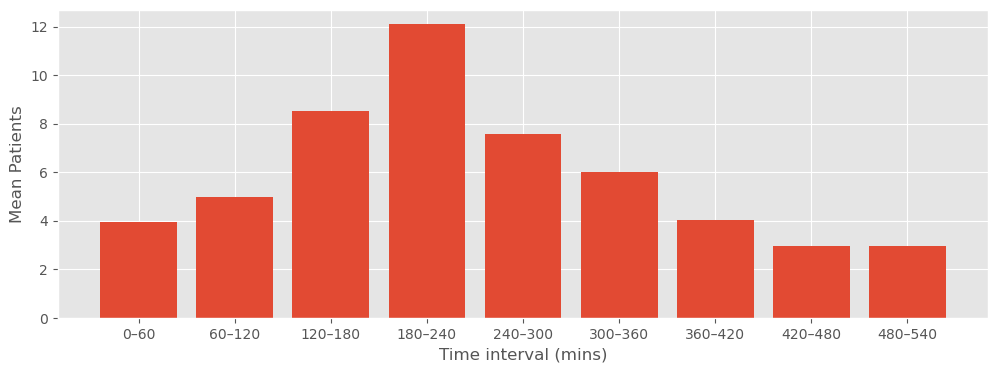

In [20]:
fig, ax = nspp_direct_plot(data2, run_length=540, n_reps=1000, include_expected=False, show_error_bars=False)
ax.set_title("")
ax.get_legend().remove()
_ = ax.set_xlabel("Time interval (mins)")
_ = ax.set_ylabel("Mean Patients")
fig.savefig("Example_Time_Dependent_Dist.png", bbox_inches="tight")

## The Direct Algorithm for Non-Stationary Poisson Processes

Harrod and Kelton (2006) present three algorithms for generating arrival times
from a non-stationary Poisson process (NSPP) with a piecewise-constant
instantaneous rate function. The **Direct Algorithm** is the simplest of the
three. It works by inverting the cumulative arrival rate function Λ(t) mapping event
times from a unit-rate Poisson process (the "arrival clock") back into
wall-clock time.



> **Reference:** Harrod, S. & Kelton, W.D. (2006). Numerical Methods for
Realizing Nonstationary Poisson Processes with Piecewise-Constant
Instantaneous-Rate Functions. *Simulation*, 82(3), 147–157.
DOI: [10.1177/0037549706065514](https://doi.org/10.1177/0037549706065514)

---

### Notation

| Symbol | Meaning |
|:------:|---------|
| $K$ | Number of piecewise-constant rate segments |
| $b_k$ | Right time-boundary of segment $k$; $b_0 = 0$ |
| $r_k$ | Constant arrival rate over segment $k$ |
| $c_k$ | Cumulative expected arrivals at $b_k$; $c_0 = 0$ |
| $S_n$ | Cumulative arrival-clock time after $n$ events |
| $T_n$ | Wall-clock time of the $n$-th arrival |

The cumulative rate boundaries are pre-computed once:

$$c_k = \sum_{i=1}^{k} r_i (b_i - b_{i-1}), \quad k = 1, \dots, K$$

---

### Pre-processing (Steps 1–4)

**Step 1.** Set $k = 1$, $S_0 = 0$, $T_0 = 0$.

**Step 2.** For each segment $k = 1, \dots, K$, compute:
$$c_k = c_{k-1} + r_k (b_k - b_{k-1})$$

**Step 3.** Set $n = 1$.

---

### Main Loop (Step 5, repeated for each arrival)

**Step 5.1.** Generate $U \sim \text{Uniform}(0, 1)$.

**Step 5.2.** Compute the unit-rate inter-arrival time:
$$A_n = -\ln(U)$$

**Step 5.3.** Advance the arrival clock:
$$S_n = S_{n-1} + A_n$$

**Step 5.4.** Find the segment $k$ such that:
$$c_{k-1} < S_n \leq c_k$$

**Step 5.5.** Invert to obtain the wall-clock arrival time:
$$T_n = b_{k-1} + \frac{S_n - c_{k-1}}{r_k}$$

**Step 5.6.** Set $n = n + 1$ and return to Step 5.1.


## How the Direct Algorithm Works

The **wall-clock time** of the simulation is the current simulated time. For example, 30, 40, or 50 minutes into a simulation run. To understand the Direct Algorithm we also need to imagine a **completely different, fictional clock**, which we call the *arrival clock*. It ticks at a rate proportional to the arrival rate at time $t$: when the real arrival rate is high (e.g., 8 arrivals/hour), the arrival clock ticks fast; when the rate is low (1 arrival/hour), it ticks slowly.

The cumulative reading on the arrival clock at time $t$ is written $\Lambda(t)$ the **cumulative rate function**. It is *not* the instantaneous rate $\lambda(t)$, but the total accumulation of rate up to time $t$.

To visualise how the Direct Algorithm works, consider the chart below. The y-axis represents $\Lambda(t)$: the **expected** cumulative number of arrivals to the system by time $t$. For example, the expected number of patients to have arrived at an Emergency Department from midnight until 1700. The x-axis represents wall-clock simulation time. An individual simulated arrival $n$ appear as points $(T_n, S_n)$ lying on this curve.

Inter-arrival times are generated by **inversion**. When a simulation is run, events are always generated at a constant rate of exactly 1 per tick of the arrival clock. The spacing between arrivals in wall-clock time is then automatically stretched or compressed depending on the rate in the current segment. When $\Lambda(t)$ is steep (high rate), a given number of arrival-clock ticks maps to a short stretch of real time, i.e., arrivals come quickly. When $\Lambda(t)$ is shallow (low rate), the same ticks map to a longer stretch, i.e., arrivals are spaced further apart. Rate changes between segments are handled seamlessly because the inversion formula always reads from the arrival clock back to the correct position on the time axis.

This is a two-step process:

1. Generate the next event on the arrival clock by drawing: $A_n = -\ln(U), \quad U \sim \text{Uniform}(0, 1)$
and advancing the arrival clock: $S_n = S_{n-1} + A_n$.

2. **Invert** $S_n$ back to wall-clock time $T_n$ by finding which segment of $\Lambda(t)$ contains $S_n$ and applying: 
$T_n = b_{k-1} + \frac{S_n - c_{k-1}}{r_k}$

The notation used in these expressions is defined in the table below, followed
by the full algorithm pseudocode.


In [ ]:
nspp_direct = NSPPDirect(data=data2)
fig = nspp_direct.plot_cumulative_rate(n_arrivals=0)
fig.show()

Think of the arrival clock as walking up the Y axis of a chart. The Y axis is plotting the number of arrivals to the system, e.g. the number of patients arriving at an Emergency Department. Along In the Direct Algorithm **On the arrival clock, arrivals always happen at a constant rate of exactly 1 per tick.**. 

So generating the NSPP becomes a two-step trick:

1. Generate arrivals at **rate 1** on the fictional arrival clock. I.e. $A_n = -\ln(U)$
2. **Convert** each fictional-clock time \(S_n\) back into real wall-clock time \(T_n\)

Step 2 is the inversion: given \(S_n\) on the arrival clock, where does that land on the real clock?

***

## The Analogy Side by Side

Think of it like two different maps of the same journey:

| | Thinning | Direct |
|---|---|---|
| **Metaphor** | Bouncer with a biased coin | Currency exchange between two clocks |
| **Working space** | Real wall-clock time | Fictional "arrival clock" time |
| **What you generate** | Arrivals at \(\lambda^*\), then accept/reject | Arrivals at rate 1 on arrival clock, then convert |
| **Where the rate info is used** | At each candidate, to set acceptance probability | Once up front, to build the conversion table (\(c_k\)) |
| **Waste** | Yes — rejects at low-rate periods | None — every draw produces a real arrival |
| **State between calls** | None — just needs current time | Yes — must remember where you are on arrival clock (\(S_n\)) |
| **Start time matters?** | No — just looks up segment from wall clock | Yes — must initialise \(S_n = \Lambda(t_\text{start})\) |

***

## A Concrete Tiny Example

Say you have two intervals:
- Hour 1: rate = 1 arrival/hour
- Hour 2: rate = 4 arrivals/hour

**Thinning** would set $\lambda^* = 4$, generate arrivals at rate 4 throughout, and accept hour-1 candidates only 1-in-4 times. Three quarters of the work in hour 1 is wasted.

**Direct** builds the arrival clock:
- End of hour 1: $c_1 = 1 \times 1 = 1$ tick
- End of hour 2: $c_2 = 1 + 4 \times 1 = 5$ ticks

Now draw $S_1 = -\ln(U) \approx 0.3$ ticks. Since $0.3 < c_1 = 1$, this is in segment 1. Convert: $T_1 = 0 + 0.3/1 = 0.3$ hours. ✓

Draw $S_2 = 0.3 + 0.9 = 1.2$ ticks. Since $1.2 > c_1 = 1$ but $1.2 \leq c_2 = 5$, this is in segment 2. Convert: $T_2 = 1 + (1.2 - 1)/4 = 1.05$ hours. ✓

No wasted draws. Every $U$ produces exactly one real arrival.

***

## A Concrete Tiny Example

Say you have three intervals:
- Hour 1: rate = 1 arrival/hour
- Hour 2: rate = 4 arrivals/hour
- Hour 3: rate = 2 arrivals/hour

**Thinning** would set $\lambda^* = 4$, generate arrivals at rate 4 throughout, and accept hour-1 candidates only 1-in-4 times and hour-3 candidates 1-in-2 times. In hour 1, three quarters of the work is wasted; in hour 3, half of it is.

**Direct** builds the arrival clock:
- End of hour 1: $c_1 = 1 \times 1 = 1$ tick
- End of hour 2: $c_2 = 1 + 4 \times 1 = 5$ ticks
- End of hour 3: $c_3 = 5 + 2 \times 1 = 7$ ticks

Note the arrival clock speeds up and slows down: it climbs 1 tick in hour 1, races 4 ticks in hour 2, then only 2 more ticks in hour 3.

Now draw $S_1 = -\ln(U) \approx 0.3$ ticks. Since $0.3 < c_1 = 1$, this is in segment 1. Convert: $T_1 = 0 + 0.3/1 = 0.3$ hours. ✓

Draw $S_2 = 0.3 + 0.9 = 1.2$ ticks. Since $1.2 > c_1 = 1$ but $1.2 \leq c_2 = 5$, this is in segment 2. Convert: $T_2 = 1 + (1.2 - 1)/4 = 1.05$ hours. ✓

Draw $S_3 = 1.2 + 0.8 = 2.0$ ticks. Still in segment 2 ($1 < 2.0 \leq 5$). Convert: $T_3 = 1 + (2.0 - 1)/4 = 1.25$ hours. ✓

Draw $S_4 = 2.0 + 3.4 = 5.4$ ticks. Now $5.4 > c_2 = 5$ but $5.4 \leq c_3 = 7$, so this is in segment 3 — the slow period. Convert: $T_4 = 2 + (5.4 - 5)/2 = 2.2$ hours. ✓

Draw $S_5 = 5.4 + 1.2 = 6.6$ ticks. Still in segment 3. Convert: $T_5 = 2 + (6.6 - 5)/2 = 2.8$ hours. ✓

Draw $S_6 = 6.6 + 1.5 = 8.1$ ticks. Since $8.1 > c_3 = 7$, this arrival falls beyond the end of the horizon — stop here (or extend the table if the sim continues).

No wasted draws. Every $U$ produces exactly one real arrival (until you run off the end of the table).

***

Watch what happens to the gaps across the fast-to-slow transition:

| $n$ | Tick gap | Segment rate | Wall-clock gap |
|---|---|---|---|
| $T_2 \to T_3$ | 0.8 ticks | 4/hour | 0.2 hours |
| $T_3 \to T_4$ | 3.4 ticks | 2/hour | 0.95 hours |
| $T_4 \to T_5$ | 1.2 ticks | 2/hour | 0.6 hours |

The tick gaps are all drawn from the same memoryless exponential with mean 1 — the arrival clock neither knows nor cares about the rates. But dividing by the segment rate stretches or squashes those gaps: 3.4 ticks in the slow segment becomes nearly a full hour of wall-clock time, while the same 3.4 ticks inside hour 2 would have been under 53 minutes... in fact, only 0.85 hours. The fast-to-slow slowdown emerges entirely from the conversion, with zero rejection along the way.



## The Same Thing in Minutes

Rates stay in arrivals per hour, but now every segment is 30 minutes long.
Each segment therefore contributes $r_k \times \frac{30}{60} = r_k / 2$ ticks —
the duration term is no longer an invisible $\times 1$:

- Minutes 0–30: rate = 6 arrivals/hour
- Minutes 30–60: rate = 2 arrivals/hour
- Minutes 60–90: rate = 4 arrivals/hour

Building the arrival clock:

- End of minute 30: $c_1 = 0 + 6 \times \frac{30}{60} = 3$ ticks
- End of minute 60: $c_2 = c_1 + 2 \times \frac{30}{60} = 3 + 1 = 4$ ticks
- End of minute 90: $c_3 = c_2 + 4 \times \frac{30}{60} = 4 + 2 = 6$ ticks

The fast-to-slow transition from earlier is still here (6 → 2 per hour),
but now the tick budget per segment is halved: 3, then just 1, then 2.

Now the draws — gaps on the arrival clock are exponential with mean 1 tick:

Draw $S_1 = 0.8$ ticks. Since $0.8 \leq c_1 = 3$, segment 1. Convert —
$(S_n - c_{k-1})/r_k$ comes out in *hours*, so $\times 60$ for minutes:
$T_1 = 0 + \frac{0.8}{6} \times 60 = 8$ minutes. ✓

Draw $S_2 = 0.8 + 1.5 = 2.3$ ticks. Still segment 1:
$T_2 = \frac{2.3}{6} \times 60 = 23$ minutes. ✓

Draw $S_3 = 2.3 + 0.9 = 3.2$ ticks. Now $c_1 = 3 < 3.2 \leq c_2 = 4$, so
segment 2. The segment *starts* at minute 30, and the leftover ticks convert
at segment 2's slower rate:
$T_3 = 30 + \frac{3.2 - 3}{2} \times 60 = 30 + 6 = 36$ minutes. ✓

Draw $S_4 = 3.2 + 0.5 = 3.7$ ticks. Still segment 2:
$T_4 = 30 + \frac{3.7 - 3}{2} \times 60 = 30 + 21 = 51$ minutes. ✓

Draw $S_5 = 3.7 + 1.6 = 5.3$ ticks. Since $c_2 = 4 < 5.3 \leq c_3 = 6$,
segment 3, which starts at minute 60:
$T_5 = 60 + \frac{5.3 - 4}{4} \times 60 = 60 + 19.5 = 79.5$ minutes. ✓

Draw $S_6 = 5.3 + 1.0 = 6.3$ ticks. Since $6.3 > c_3 = 6$, this arrival falls
beyond the end of the horizon — stop.

Every unit conversion happens in exactly one place: $\div 60$ when building
the $c_k$ table (minutes → hours), $\times 60$ when reading arrival times
back out (hours → minutes). The ticks themselves are unit-free — they're
just "expected arrivals so far".




## Why Direct Has Statefulness But Thinning Doesn't

This is the crucial practical difference. In thinning, each call is completely self-contained: "what time is it right now? look up rate, flip coin."  In the direct algorithm, the arrival clock \(S_n\) must accumulate continuously — you can't reconstruct where you are on the arrival clock just from the wall-clock time, because \(S_n\) depends on the entire history of random draws.  That's why `NSPPDirect` stores `_Sn_prev` and `_Tn_prev` between calls, and why `reset()` is necessary between replications. [orsagouge.pbworks](https://orsagouge.pbworks.com/f/Harrod2006.pdf)

In [ ]:
%timeit nspp_reps_direct = nspp_direct_simulation(data2, n_reps=1000)

In [ ]:
%timeit nspp_reps_thin = nspp_simulation(data, n_reps=1000)

In [ ]:
fig, ax = nspp_plot(data2, run_length=540, n_reps=1000)

In [ ]:
# Full Figure with 50 simulated arrivals and projection lines
fig = nspp.plot_cumulative_rate(
    n_arrivals=50, 
    random_seed=42, 
    show_grid_lines=True,
    units_y="Customers",
    units_x="mins"
)
fig.show()   # interactive in Jupyter / Quarto